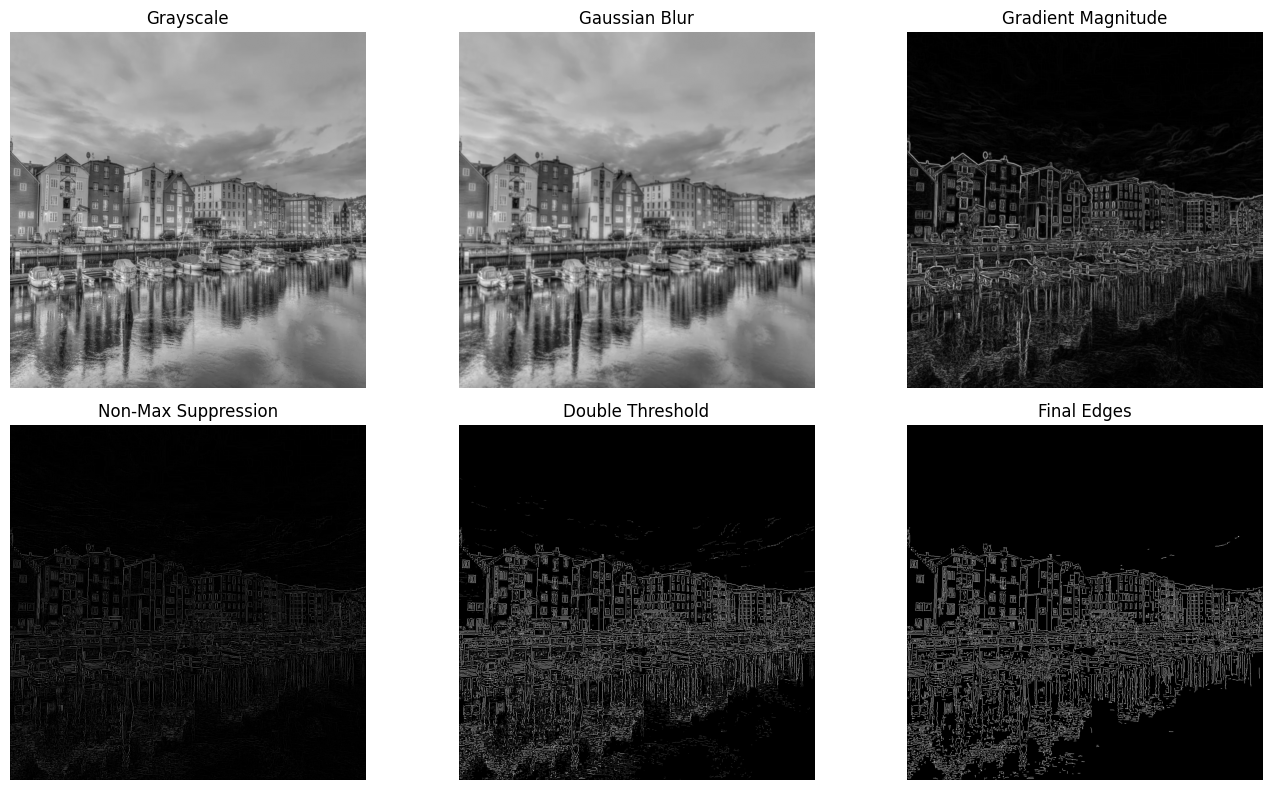

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def canny_edge_detector(image_path="boats.jpg", sigma=1.2, low_thresh=20, high_thresh=50):
    results = []

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    results.append(image)

    # Gaussian Blur
    blurred = cv2.GaussianBlur(image, (5, 5), sigma)
    results.append(blurred)

    # Sobel kernels
    sobel_x = np.array([[-1, 0, 1],
                        [-2, 0, 2],
                        [-1, 0, 1]], dtype=np.float32)

    sobel_y = np.array([[-1, -2, -1],
                        [ 0,  0,  0],
                        [ 1,  2,  1]], dtype=np.float32)

    Gx = cv2.filter2D(blurred, cv2.CV_64F, sobel_x)
    Gy = cv2.filter2D(blurred, cv2.CV_64F, sobel_y)

    # Gradient magnitude & direction
    magnitude = np.sqrt(Gx**2 + Gy**2)
    magnitude = (magnitude / magnitude.max()) * 255
    magnitude = magnitude.astype(np.uint8)
    results.append(magnitude)

    angle = np.arctan2(Gy, Gx)
    angle = np.rad2deg(angle)
    angle[angle < 0] += 180

    # NMS
    h, w = magnitude.shape
    NMS = np.zeros((h, w), dtype=np.uint8)

    for i in range(1, h-1):
        for j in range(1, w-1):
            first = 0
            second = 0

            if (0 <= angle[i,j] < 22.5) or (157.5 <= angle[i,j] <= 180):
                first = magnitude[i, j+1]
                second = magnitude[i, j-1]
            elif 22.5 <= angle[i,j] < 67.5:
                first = magnitude[i+1, j-1]
                second = magnitude[i-1, j+1]
            elif 67.5 <= angle[i,j] < 112.5:
                first = magnitude[i+1, j]
                second = magnitude[i-1, j]
            elif 112.5 <= angle[i,j] < 157.5:
                first = magnitude[i-1, j-1]
                second = magnitude[i+1, j+1]

            if magnitude[i,j] >= first and magnitude[i,j] >= second:
                NMS[i,j] = magnitude[i,j]
            else:
                NMS[i,j] = 0

    results.append(NMS)

    # Double Threshold
    STRONG = 255
    WEAK = 75

    thresholded = np.zeros_like(NMS, dtype=np.uint8)

    strong_i, strong_j = np.where(NMS >= high_thresh)
    weak_i, weak_j = np.where((NMS >= low_thresh) & (NMS < high_thresh))

    thresholded[strong_i, strong_j] = STRONG
    thresholded[weak_i, weak_j] = WEAK

    results.append(thresholded)

    # HYSTERESIS
    final_edges = thresholded.copy()

    for i in range(1, h-1):
        for j in range(1, w-1):
            if final_edges[i,j] == WEAK:
                if np.any(final_edges[i-1:i+2, j-1:j+2] == STRONG):
                    final_edges[i,j] = STRONG
                else:
                    final_edges[i,j] = 0

    results.append(final_edges)

    # Display results
    titles = [
        "Grayscale",
        "Gaussian Blur",
        "Gradient Magnitude",
        "Non-Max Suppression",
        "Double Threshold",
        "Final Edges"
    ]

    plt.figure(figsize=(14, 8))
    for i in range(len(results)):
        plt.subplot(2, 3, i+1)
        plt.imshow(results[i], cmap='gray')
        plt.title(titles[i])
        plt.axis('off')

    plt.tight_layout()
    plt.show()


canny_edge_detector(image_path="boats.jpg", sigma=1.2, low_thresh=20, high_thresh=50)